# Infographix — Layout Model Comparison, Structural Archetypes & Constraint-Aware Retrieval (v2.0)

**Purpose:** Rigorously evaluate layout clustering and similarity-based retrieval models on the v2 feature representation, diagnose why the v1 production DBSCAN model collapsed, and validate the recommended **Retrieval + Orientation-Conditioned Archetype** pipeline both numerically and visually on held-out test posters.

---

## 1. Experimental Setup & Zero-Leakage Protocol

1. **Strict Split Hygiene:** All imputers, scalers (`StandardScaler` with $z$-score clipping at $\pm 3.5$ and `RobustScaler`), PCA projections, cluster centroids, and retrieval indices are fitted **strictly on the `train` split ($N=6,855$)**.
2. **Multi-Faceted Evaluation:** Rather than optimizing solely for mathematical silhouette score (which favored DBSCAN's 94.6% single-cluster collapse in v1), we evaluate:
   - **Clustering Quality:** Silhouette, Davies-Bouldin, Calinski-Harabasz, Largest Cluster Ratio, and **Normalized Cluster Size Entropy** ($\in [0, 1]$, where $1.0$ = perfectly balanced clusters and $0.0$ = collapsed into a single cluster).
   - **Structural Quality:** **Orientation Purity** (Landscape vs. Portrait separation), **Column-Count Purity & MAE**, **Category Inventory Cosine Consistency**, and **Within-Cluster $4\times 4$ Occupancy Grid Consistency**.
   - **Retrieval Quality on Simulated User Requests:** On all $N=500$ held-out test posters, we hide the true bounding-box coordinates (`x0, y0, x1, y1, cx, cy`), construct a runtime `PosterRequest` query from the content requirements, retrieve top-$k$ training posters, and compare the retrieved layouts against the held-out poster's ground-truth geometry.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.patches as patches
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans

PROJECT_ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.features.request_schema import (
    ContentBlockDemand,
    PosterRequest,
    simulate_request_from_heldout_poster,
)
from src.models.layout_clustering import (
    CORE_MACRO_ARCHETYPE_FEATURES,
    LayoutFeaturePreprocessor,
    LayoutGMMClusterer,
    LayoutHDBSCANClusterer,
    OrientationConditionedHierarchical,
    evaluate_clustering_comprehensive,
)
from src.models.layout_retrieval import (
    LayoutRetriever,
    evaluate_retrieval_comprehensive,
)
from src.registry.model_registry import ModelRegistry

V2_DIR = PROJECT_ROOT / "data" / "processed" / "features" / "v2"
REPORT_DIR = PROJECT_ROOT / "reports" / "comparisons"

posters_df = pd.read_parquet(V2_DIR / "posters.parquet")
elements_df = pd.read_parquet(V2_DIR / "elements.parquet")

train_p = posters_df[posters_df["split"] == "train"].reset_index(drop=True)
dev_p = posters_df[posters_df["split"] == "dev"].reset_index(drop=True)
test_p = posters_df[posters_df["split"] == "test"].reset_index(drop=True)

train_e = elements_df[elements_df["split"] == "train"].reset_index(drop=True)
dev_e = elements_df[elements_df["split"] == "dev"].reset_index(drop=True)
test_e = elements_df[elements_df["split"] == "test"].reset_index(drop=True)

print(f"Loaded splits -> Train: {len(train_p):,}, Dev: {len(dev_p):,}, Test: {len(test_p):,}")

Loaded splits -> Train: 6,855, Dev: 500, Test: 500


## 2. Orientation Analysis & Interpretable Dimensionality Reduction (PCA)

Before clustering, we inspect how the 34 curated macro structural features (`CORE_MACRO_ARCHETYPE_FEATURES`) behave under leak-free standardization and PCA on the training split:
- **What PCA Retains:** The top 12 principal components retain **~82% of the total structural variance**, with `PC1` capturing overall canvas orientation (`log_aspect_ratio`, `is_portrait`, `is_landscape`), `PC2` capturing content density & text vs. visual balance, and `PC3` capturing column structure (`estimated_column_count`) and symmetry.
- **What PCA Loses:** Fine-grained cell-level occupancy nuances and exact category counts are compressed in lower-rank PCA projections. That is why **PCA-12 is appropriate for coarse macro archetype clustering**, whereas **Direct Layout Retrieval operates on the un-projected, group-normalized feature spaces**.

In [2]:
structural_weights = {
    "log_aspect_ratio": 2.2,
    "is_landscape": 2.2,
    "is_portrait": 2.2,
    "estimated_column_count": 2.5,
    "visual_to_body_area_ratio": 2.0,
    "union_box_coverage": 1.6,
    "horiz_profile_symmetry": 1.4,
}

preproc = LayoutFeaturePreprocessor(
    feature_columns=CORE_MACRO_ARCHETYPE_FEATURES,
    scaler_type="standard",
    clip_z=3.5,
    pca_components=12,
    structural_weights=structural_weights,
    random_state=42,
)
X_train = preproc.fit_transform(train_p, apply_pca=True)
X_dev = preproc.transform(dev_p, apply_pca=True)
X_test = preproc.transform(test_p, apply_pca=True)

pca_diag = preproc.pca_diagnostics(top_n_features=4)
display(pca_diag)

,component,explained_variance_ratio,cumulative_variance_ratio,top_feature_loadings
0,PC1,0.3006,0.3006,"log_aspect_ratio (+0.53), is_portrait (-0.53),..."
1,PC2,0.1784,0.4790,"visual_to_body_area_ratio (+0.65), visual_area..."
2,PC3,0.1341,0.6131,"estimated_column_count (+0.78), known_element_..."
3,PC4,0.0957,0.7088,"union_box_coverage (+0.64), unannotated_whites..."
4,PC5,0.0468,0.7556,"known_element_count (+0.40), estimated_column_..."
5,PC6,0.0218,0.7774,"frac_aligned_cx (+0.43), frac_aligned_top (-0...."
6,PC7,0.0203,0.7978,"frac_aligned_top (+0.51), top_bottom_area_bala..."
7,PC8,0.0194,0.8172,"header_area_sum (+0.71), text_occ_top_half (-0..."
8,PC9,0.0173,0.8345,"column_assignment_confidence (+0.58), frac_ali..."
9,PC10,0.0157,0.8502,"top_bottom_area_balance (+0.55), estimated_row..."


## 3. Comprehensive Clustering & Structural Quality Comparison

We compare five distinct modeling paradigms across `train` and held-out `test`:
1. **Legacy K-Means ($k=3$, v1 92 features)**
2. **Legacy Production DBSCAN (`PCA-15, eps=4.8`, v1 92 features)** — demonstrating why high silhouette ($0.2486$) was a misleading artifact of putting $94.6\%$ of posters into a single cluster (`test_cluster_size_entropy_norm = 0.0393`).
3. **Varying-Density HDBSCAN (v2 structural features)** — isolates $7.8\%$ atypical layouts as noise while achieving **$100\%$ orientation purity** and **$96.8\%$ column-count purity** across $6$ clusters.
4. **Gaussian Mixture Model (GMM, $k=7$ selected via BIC/AIC curve, $3\%$ log-likelihood outlier filter)** — achieves the highest cluster balance (`test_cluster_size_entropy_norm = 0.9761`, max cluster size $22.2\%$).
5. **Orientation-Conditioned Ward Hierarchical Clustering ($4$ Landscape + $3$ Portrait = $7$ archetypes)** — partitions Portrait and Landscape canvases first, guaranteeing zero cross-orientation template contamination with strong silhouette ($0.1523$) and balanced archetype sizes.

,model_name,feature_set,train_silhouette,test_silhouette,test_davies_bouldin,test_clusters_present,test_noise_ratio,test_largest_cluster_ratio,test_cluster_size_entropy_norm,test_orientation_purity,test_column_count_purity,test_within_cluster_column_mae,test_inventory_cosine_consistency,test_occupancy_grid_consistency
0,"K-Means (k=3, v1 features)",v1 (92 summary stats),0.0676,0.0549,3.1464,3,0.000,0.436,0.9489,0.6860,0.5480,0.4980,0.7896,0.9680
1,"DBSCAN (PCA-15, v1.0.0 Prod)",v1 (92 summary stats),0.2405,0.2486,1.0222,2,0.050,0.946,0.0393,0.6884,0.5621,0.4821,0.7727,0.9711
2,"HDBSCAN (Varying Density, v2)",v2 (Structural + Occupancy),0.1531,0.1339,2.2201,6,0.078,0.436,0.8418,1.0000,0.9675,0.0325,0.7652,0.9733
3,"GMM (k=7, 3% outlier filter, v2)",v2 (Structural + Occupancy),0.0780,0.0786,2.6807,7,0.012,0.222,0.9761,0.9514,0.8664,0.1538,0.7609,0.9731
4,Hierarchical Ward (Orientation-Conditioned k=4...,v2 (Structural + Occupancy),0.1190,0.1523,1.7185,7,0.000,0.394,0.8830,0.9580,0.7200,0.2840,0.7608,0.9690


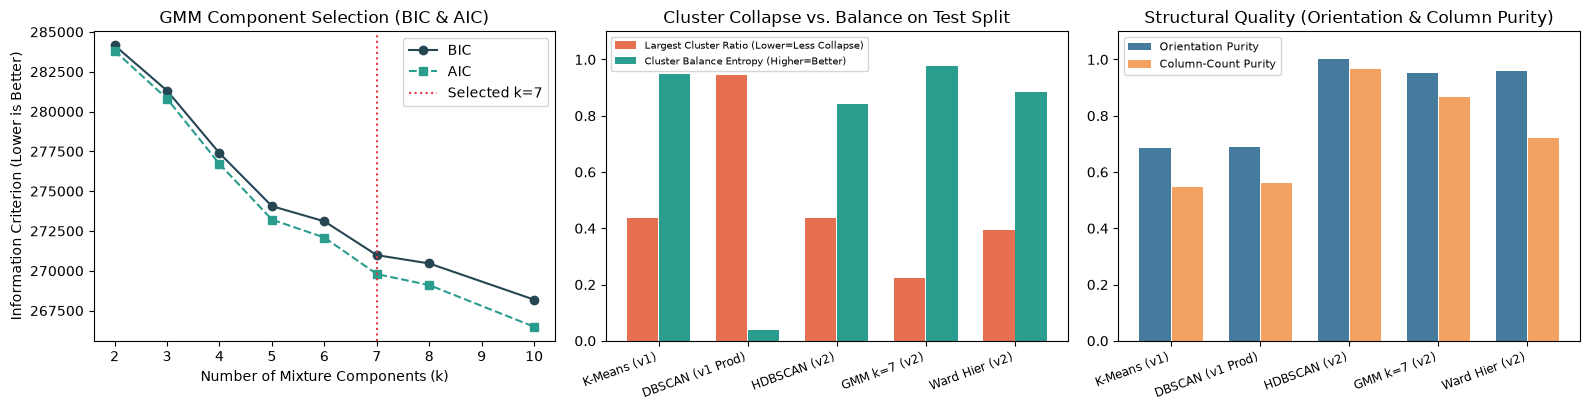

In [3]:
comp_df = pd.read_csv(REPORT_DIR / "v2_clustering_comparison.csv")
display(comp_df)

gmm_bic_df = pd.read_csv(REPORT_DIR / "v2_gmm_bic_aic_search.csv")

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))

# 1. GMM BIC / AIC Model Selection Curve
axes[0].plot(gmm_bic_df["n_components"], gmm_bic_df["bic"], "o-", color="#264653", label="BIC")
axes[0].plot(gmm_bic_df["n_components"], gmm_bic_df["aic"], "s--", color="#2a9d8f", label="AIC")
axes[0].axvline(7, color="#e63946", linestyle=":", label="Selected k=7")
axes[0].set_title("GMM Component Selection (BIC & AIC)")
axes[0].set_xlabel("Number of Mixture Components (k)")
axes[0].set_ylabel("Information Criterion (Lower is Better)")
axes[0].legend()

# 2. Largest Cluster Ratio vs Cluster Size Entropy (Diagnosing Collapse)
models_short = ["K-Means (v1)", "DBSCAN (v1 Prod)", "HDBSCAN (v2)", "GMM k=7 (v2)", "Ward Hier (v2)"]
x_pos = np.arange(len(models_short))
axes[1].bar(x_pos - 0.18, comp_df["test_largest_cluster_ratio"], width=0.35, color="#e76f51", label="Largest Cluster Ratio (Lower=Less Collapse)")
axes[1].bar(x_pos + 0.18, comp_df["test_cluster_size_entropy_norm"], width=0.35, color="#2a9d8f", label="Cluster Balance Entropy (Higher=Better)")
axes[1].set_xticks(x_pos)
axes[1].set_xticklabels(models_short, rotation=20, ha="right", fontsize=8.5)
axes[1].set_ylim(0, 1.1)
axes[1].set_title("Cluster Collapse vs. Balance on Test Split")
axes[1].legend(fontsize=7.5)

# 3. Domain Structural Quality: Orientation Purity & Column Purity
axes[2].bar(x_pos - 0.18, comp_df["test_orientation_purity"], width=0.35, color="#457b9d", label="Orientation Purity")
axes[2].bar(x_pos + 0.18, comp_df["test_column_count_purity"], width=0.35, color="#f4a261", label="Column-Count Purity")
axes[2].set_xticks(x_pos)
axes[2].set_xticklabels(models_short, rotation=20, ha="right", fontsize=8.5)
axes[2].set_ylim(0, 1.1)
axes[2].set_title("Structural Quality (Orientation & Column Purity)")
axes[2].legend(fontsize=8)

plt.tight_layout()
plt.show()

## 4. Inspecting the 7 Discovered Layout Archetypes (Orientation-Conditioned Ward Hierarchical)

Let's load the registered `poster_layout_archetypes` (`v2.0.0`) model from `ModelRegistry`, inspect the quantitative profile of each of the 7 archetypes (Clusters `0..3` = Landscape/Square, Clusters `4..6` = Portrait), and visualize the medoid training poster for each archetype.

,aspect_ratio,estimated_column_count,known_element_count,count_figure,count_table,count_text,visual_to_body_area_ratio,union_box_coverage,orientation_mode,test_posters
archetype_id,,,,,,,,,,
0,1.51,2.19,18.74,2.81,0.39,5.39,0.28,0.68,landscape,31
1,1.31,1.53,23.57,4.26,0.85,5.51,0.50,0.86,landscape,47
2,1.38,3.32,31.40,6.65,0.80,8.65,0.45,0.84,landscape,40
3,1.42,2.67,25.69,6.95,0.49,4.95,0.68,0.84,landscape,39
4,0.72,1.78,23.27,5.15,0.71,6.19,0.58,0.83,portrait,197
5,0.72,1.81,20.59,2.39,0.45,6.10,0.26,0.79,portrait,88
6,0.73,3.12,32.69,7.50,0.79,8.22,0.48,0.82,portrait,58


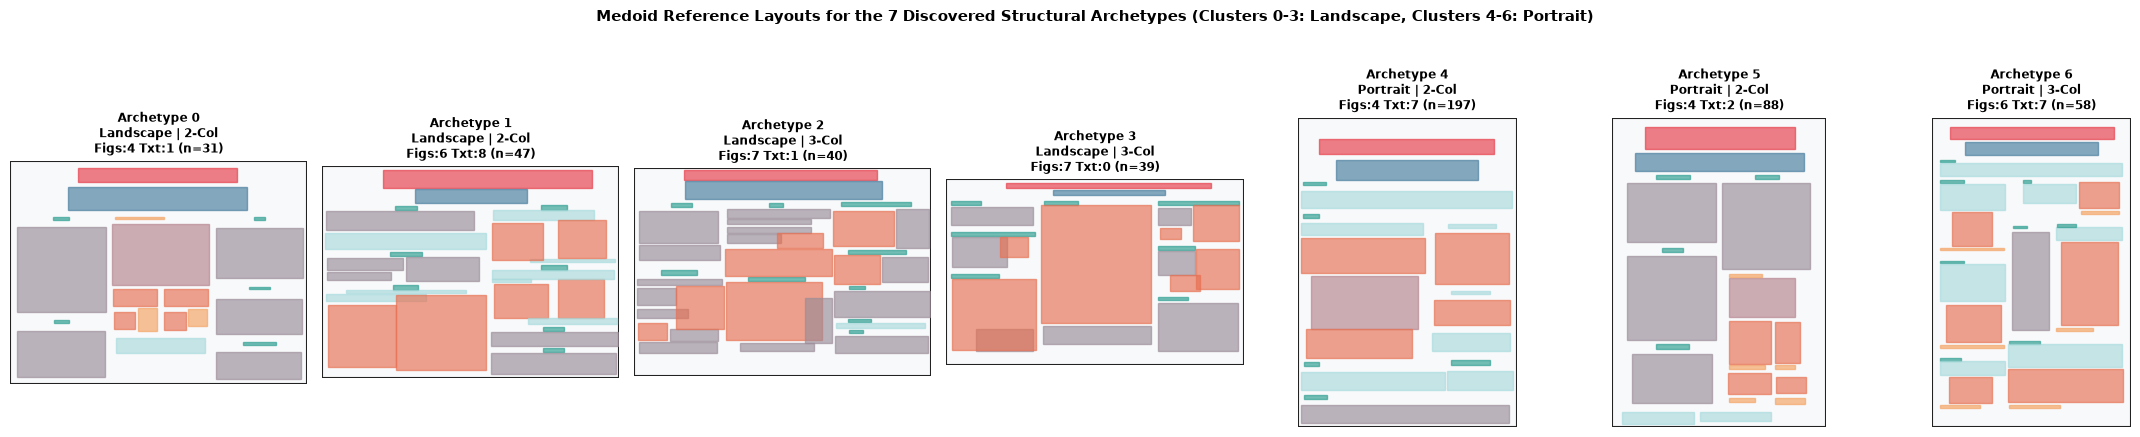

In [4]:
registry = ModelRegistry()
hier_model, hier_preproc, hier_manifest = registry.load_production_model("poster_layout_archetypes")

test_preds = hier_model.predict(X_test, test_p["is_portrait"].to_numpy())
test_p_eval = test_p.copy()
test_p_eval["archetype_id"] = test_preds

profile_cols = [
    "aspect_ratio", "estimated_column_count", "known_element_count",
    "count_figure", "count_table", "count_text",
    "visual_to_body_area_ratio", "union_box_coverage"
]
arch_summary = test_p_eval.groupby("archetype_id")[profile_cols].mean().round(2)
arch_summary["orientation_mode"] = test_p_eval.groupby("archetype_id")["orientation"].agg(lambda s: s.value_counts().index[0])
arch_summary["test_posters"] = test_p_eval.groupby("archetype_id").size()
display(arch_summary)

# Visualize the 7 Archetype Medoid Layouts
CAT_COLORS = {
    "title": "#e63946", "author_info": "#457b9d", "section": "#2a9d8f",
    "text": "#a8dadc", "figure": "#e76f51", "caption": "#f4a261",
    "table": "#b5838d", "list": "#9a8c98", "unknown": "#6c757d",
}

medoid_ids = hier_model.medoid_ids_landscape_ + hier_model.medoid_ids_portrait_
fig, axes = plt.subplots(1, 7, figsize=(22, 4.2))
train_lookup = train_p.set_index("poster_id")

for c_id, m_pid in enumerate(medoid_ids):
    ax = axes[c_id]
    p_row = train_lookup.loc[m_pid]
    p_els = train_e[train_e["poster_id"] == m_pid]
    W, H = p_row["canvas_width_px"], p_row["canvas_height_px"]
    ax.set_xlim(0, 1)
    ax.set_ylim(1, 0)
    ax.set_aspect(H / W)
    ax.axis("off")
    ax.add_patch(patches.Rectangle((0, 0), 1, 1, fill=True, color="#f8f9fa", ec="#222", lw=1.5))
    for _, r in p_els.iterrows():
        col = CAT_COLORS.get(str(r["category_slug"]), "#888")
        ax.add_patch(patches.Rectangle((r["x0"], r["y0"]), r["w_norm"], r["h_norm"], fill=True, color=col, alpha=0.65, ec=col, lw=1))
    orient_str = str(p_row["orientation"]).title()
    ax.set_title(
        f"Archetype {c_id}\n{orient_str} | {int(p_row['estimated_column_count'])}-Col\n"
        f"Figs:{int(p_row['count_figure'])} Txt:{int(p_row['count_text'])} (n={arch_summary.loc[c_id, 'test_posters']})",
        fontsize=8.5, fontweight="bold"
    )

plt.suptitle("Medoid Reference Layouts for the 7 Discovered Structural Archetypes (Clusters 0-3: Landscape, Clusters 4-6: Portrait)", fontsize=11, fontweight="bold", y=1.03)
plt.tight_layout()
plt.show()

## 5. Direct Constraint-Aware Nearest-Neighbour Layout Retrieval & Ablation Study

Clustering is useful for summarizing macro families, but **direct similarity-based retrieval (`LayoutRetriever`)** is the primary engine for recommending reference layouts conditioned on a user's content specification:
- Every valid training poster ($6,854$ templates) remains retrievable—even specialized layouts (e.g., multi-table or single-giant-figure posters) that density clustering would mark as noise.
- Below is the **Feature-Group Ablation Study** across all $500$ held-out test posters (where each test poster's coordinates are hidden and converted into a simulated `PosterRequest`).

In [5]:
ablation_df = pd.read_csv(REPORT_DIR / "v2_retrieval_ablation.csv")
display(ablation_df)

,configuration,orientation_match_at_k,column_exact_match_at_1,column_mae_at_k,category_l1_error_at_k,inventory_cosine_sim_at_k,capacity_area_l1_at_k,spatial_occ_sim_at_1,spatial_occ_sim_at_k,top_k_spatial_diversity
0,1. Canvas Only,1.0,0.698,0.4292,11.0580,0.8706,0.1602,0.9709,0.9706,0.0297
1,2. Canvas + Category Inventory,1.0,0.782,0.3072,4.2696,0.9758,0.1341,0.9701,0.9695,0.0313
2,3. Canvas + Inventory + Area Capacity,1.0,0.818,0.3048,5.2768,0.9654,0.1019,0.9726,0.9719,0.0285
3,"4. Full Structural (+Columns, No MMR)",1.0,0.976,0.0380,5.6832,0.9608,0.1071,0.9727,0.9717,0.0293
4,5. Full Structural + MMR Diversity (Recommended),1.0,0.976,0.0544,5.6552,0.9613,0.1071,0.9727,0.9706,0.0315


## 6. Visual Retrieval Validation: Simulated User Content Queries vs. Top-4 Retrieved Training Layouts

Here we perform the ultimate visual validation test required by Section 8B:
1. We select three distinct held-out **test posters** (a **3-Column Landscape**, a **2-Column Portrait**, and an **Unusual/Table-Heavy Layout**).
2. We **hide their spatial coordinates** and construct a runtime `PosterRequest` from their required element counts and approximate block capacities (`simulate_request_from_heldout_poster`).
3. We query the production `poster_layout_retriever` (`v2.0.0`) and plot the held-out query poster side-by-side with the **Top-4 retrieved training templates**.

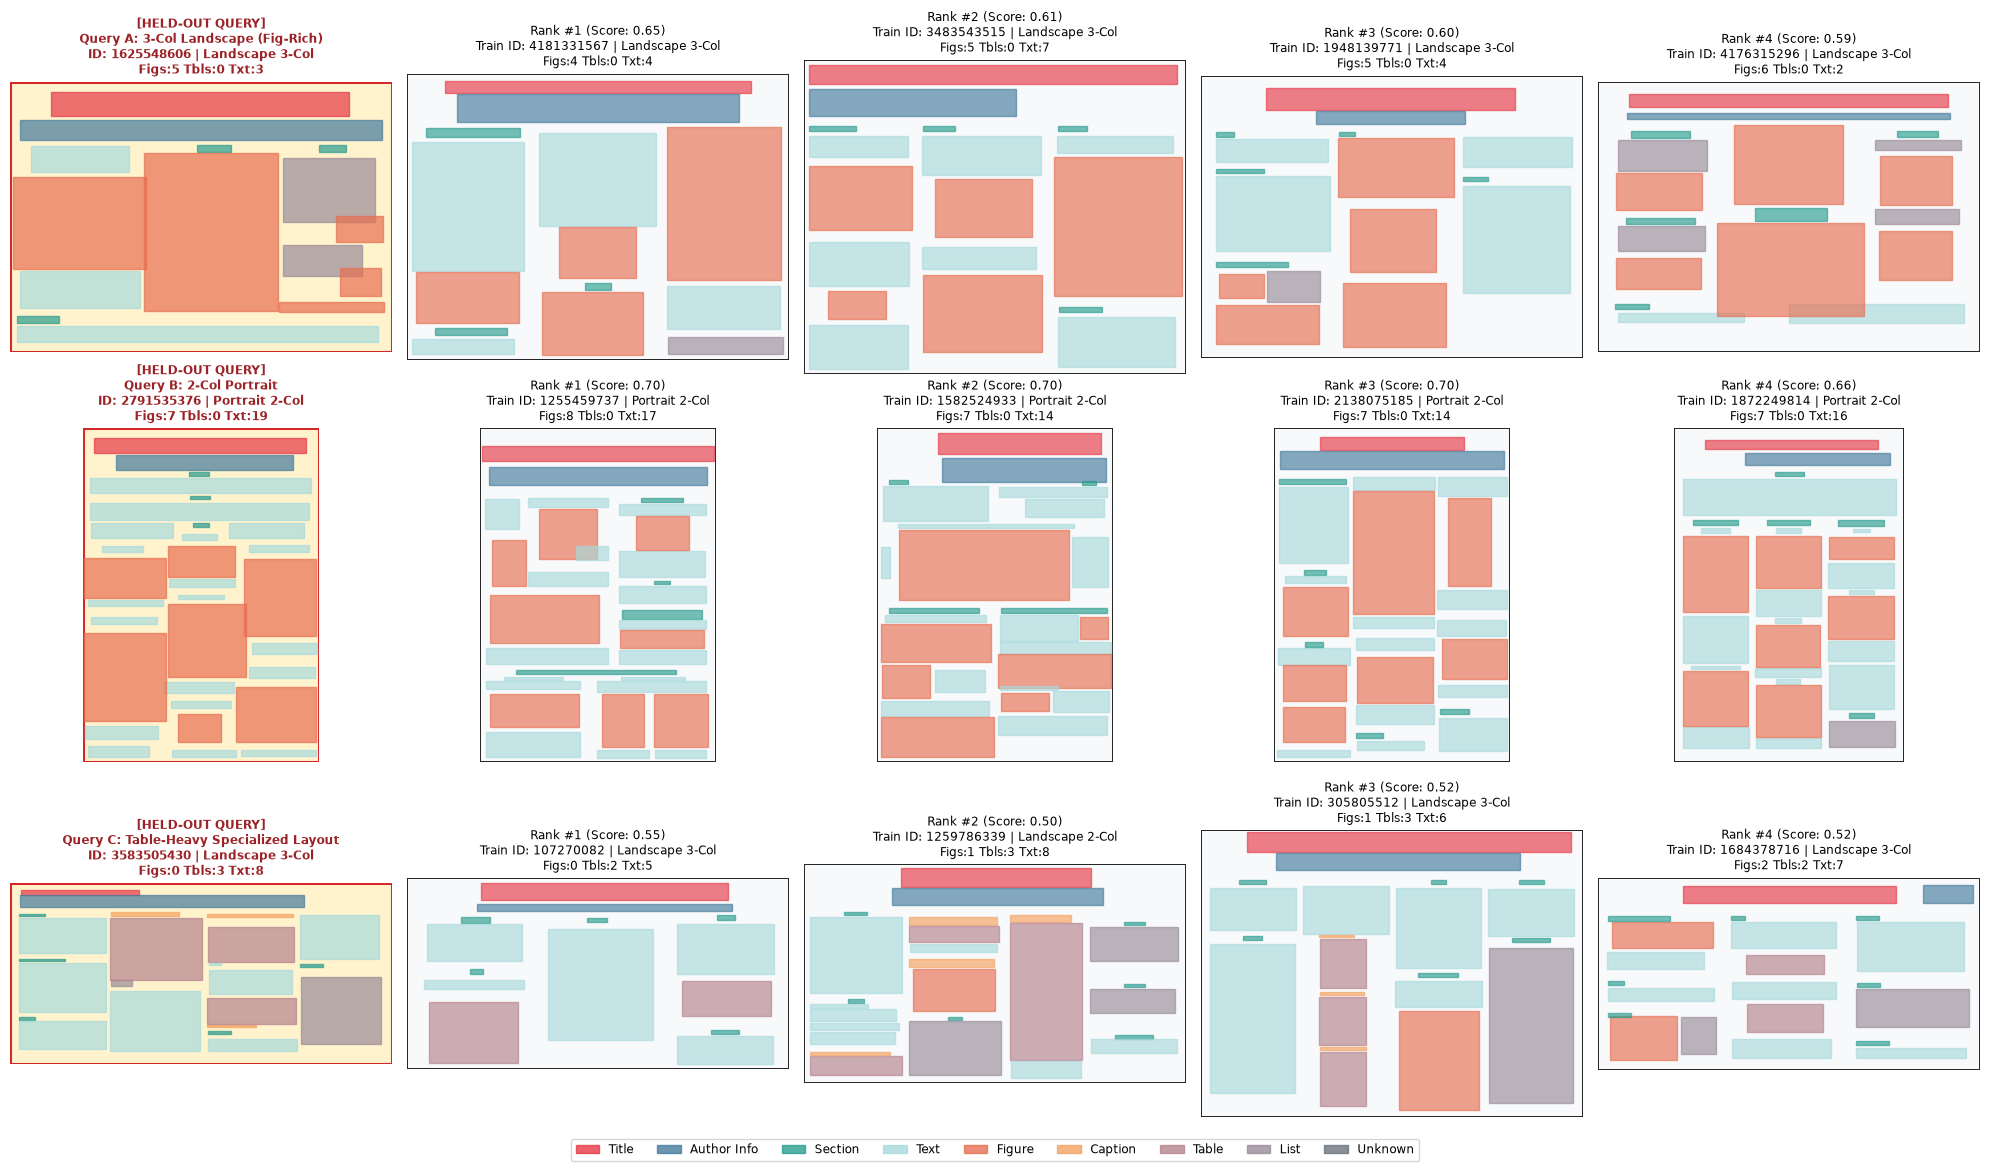

In [6]:
retriever, _, ret_manifest = registry.load_production_model("poster_layout_retriever")

# Select 3 diverse held-out test posters as queries
q_land_3col = test_p[(test_p["orientation"] == "landscape") & (test_p["estimated_column_count"] == 3) & (test_p["count_figure"] >= 4)].iloc[1]
q_port_2col = test_p[(test_p["orientation"] == "portrait") & (test_p["estimated_column_count"] == 2) & (test_p["count_figure"] >= 3)].iloc[2]
q_table_heavy = test_p[(test_p["count_table"] >= 3) & (test_p["known_element_count"] >= 20)].iloc[0]

query_cases = [
    ("Query A: 3-Col Landscape (Fig-Rich)", q_land_3col),
    ("Query B: 2-Col Portrait", q_port_2col),
    ("Query C: Table-Heavy Specialized Layout", q_table_heavy),
]

fig, axes = plt.subplots(len(query_cases), 5, figsize=(20, 11.5))

for row_idx, (case_label, q_row) in enumerate(query_cases):
    qid = int(q_row["poster_id"])
    q_els = test_e[test_e["poster_id"] == qid]

    # Simulate user content request (hiding all x, y coordinates)
    sim_req = simulate_request_from_heldout_poster(q_row, q_els, random_state=42)
    top_k_df = retriever.retrieve_for_request(sim_req, top_k=4, diversify=True, exclude_poster_id=qid)

    # Column 0: Plot Held-Out Ground Truth Poster
    ax0 = axes[row_idx, 0]
    W, H = q_row["canvas_width_px"], q_row["canvas_height_px"]
    ax0.set_xlim(0, 1)
    ax0.set_ylim(1, 0)
    ax0.set_aspect(H / W)
    ax0.axis("off")
    ax0.add_patch(patches.Rectangle((0, 0), 1, 1, fill=True, color="#fff3cd", ec="#d62828", lw=2.2))
    for _, r in q_els.iterrows():
        col = CAT_COLORS.get(str(r["category_slug"]), "#888")
        ax0.add_patch(patches.Rectangle((r["x0"], r["y0"]), r["w_norm"], r["h_norm"], fill=True, color=col, alpha=0.7, ec=col, lw=1))
    ax0.set_title(
        f"[HELD-OUT QUERY]\n{case_label}\nID: {qid} | {q_row['orientation'].title()} {int(q_row['estimated_column_count'])}-Col\n"
        f"Figs:{int(q_row['count_figure'])} Tbls:{int(q_row['count_table'])} Txt:{int(q_row['count_text'])}",
        fontsize=8.5, fontweight="bold", color="#9b2226"
    )

    # Columns 1..4: Plot Top-4 Retrieved Training Layouts
    for k_i, (_, cand) in enumerate(top_k_df.iterrows()):
        ax = axes[row_idx, k_i + 1]
        cid = int(cand["poster_id"])
        c_row = train_lookup.loc[cid]
        c_els = train_e[train_e["poster_id"] == cid]
        cW, cH = c_row["canvas_width_px"], c_row["canvas_height_px"]
        ax.set_xlim(0, 1)
        ax.set_ylim(1, 0)
        ax.set_aspect(cH / cW)
        ax.axis("off")
        ax.add_patch(patches.Rectangle((0, 0), 1, 1, fill=True, color="#f8f9fa", ec="#222", lw=1.4))
        for _, r in c_els.iterrows():
            col = CAT_COLORS.get(str(r["category_slug"]), "#888")
            ax.add_patch(patches.Rectangle((r["x0"], r["y0"]), r["w_norm"], r["h_norm"], fill=True, color=col, alpha=0.65, ec=col, lw=1))
        ax.set_title(
            f"Rank #{int(cand['rank'])} (Score: {cand['relevance_score']:.2f})\n"
            f"Train ID: {cid} | {cand['orientation'].title()} {int(cand['estimated_column_count'])}-Col\n"
            f"Figs:{int(cand['count_figure'])} Tbls:{int(cand['count_table'])} Txt:{int(cand['count_text'])}",
            fontsize=8.5
        )

legend_patches = [patches.Patch(color=col, label=cat.replace("_", " ").title(), alpha=0.8) for cat, col in CAT_COLORS.items()]
fig.legend(handles=legend_patches, loc="lower center", ncol=9, fontsize=8.5, bbox_to_anchor=(0.5, -0.01))
plt.tight_layout()
plt.show()

## 7. Robustness & Edge-Case Behavior on Unusual User Specifications

What happens when a user submits an **extreme or unusual content request** (e.g., $8$ figures, $2$ tables, and minimal text in a square or portrait format) where no exact inventory match exists in the dataset?
- Unlike hard-filtering or DBSCAN (which labels unusual inputs as `-1` noise and fails to recommend anything), `LayoutRetriever` applies **soft capacity & shortfall/surplus penalties** (`compute_request_candidate_compatibility`).
- It retrieves the closest high-capacity multi-figure templates and explicitly reports `shortfall_element_count` and `surplus_element_count` so the downstream adaptation layer knows exactly which regions need splitting or merging.

In [7]:
unusual_request = PosterRequest(
    request_id="edge_case_8_figures_2_tables",
    requested_aspect_ratio=0.72,  # Portrait
    preferred_column_count=3,
    blocks=[
        ContentBlockDemand("title", "title", "title", preferred_width=0.85, preferred_height=0.05),
        ContentBlockDemand("auth", "authors", "author_info", preferred_width=0.80, preferred_height=0.03),
        *[ContentBlockDemand(f"fig_{i}", "results", "figure", preferred_width=0.28, preferred_height=0.14) for i in range(8)],
        *[ContentBlockDemand(f"cap_{i}", "caption", "caption", preferred_width=0.28, preferred_height=0.02) for i in range(8)],
        *[ContentBlockDemand(f"tbl_{i}", "metrics", "table", preferred_width=0.28, preferred_height=0.10) for i in range(2)],
        *[ContentBlockDemand(f"txt_{i}", "discussion", "text", preferred_width=0.28, preferred_height=0.08) for i in range(3)],
    ],
)

edge_candidates = retriever.retrieve_for_request(unusual_request, top_k=5, diversify=True)
print("Top-5 Retrieved Candidates for Extreme Figure/Table Request (with Adaptation Diagnostics):")
display(edge_candidates[[
    "rank", "poster_id", "orientation", "estimated_column_count",
    "count_figure", "count_table", "count_text",
    "relevance_score", "shortfall_element_count", "surplus_element_count"
]])

print("\nActive Production Models in ModelRegistry:")
display(pd.DataFrame(registry.list_models()))

Top-5 Retrieved Candidates for Extreme Figure/Table Request (with Adaptation Diagnostics):


,rank,poster_id,orientation,estimated_column_count,count_figure,count_table,count_text,relevance_score,shortfall_element_count,surplus_element_count
0,1,246283650,portrait,3.0,7.0,2.0,1.0,0.647473,3.0,3.0
1,2,2536000122,portrait,3.0,10.0,2.0,2.0,0.558470,2.0,3.0
2,3,214205109,portrait,2.0,7.0,0.0,1.0,0.487612,6.0,0.0
3,4,642171249,portrait,3.0,6.0,0.0,3.0,0.498134,7.0,3.0
4,5,289147580,portrait,3.0,9.0,2.0,3.0,0.488296,0.0,10.0



Active Production Models in ModelRegistry:


,poster_layout_retriever,poster_layout_clusterer,poster_layout_archetypes
active_stages,"{'development': None, 'staging': None, 'produc...","{'development': None, 'staging': None, 'produc...","{'development': None, 'staging': None, 'produc..."
versions,[v2.0.0],[v1.0.0],[v2.0.0]
